# ARSET | Assessing Biodiversity Using Forest Structure from Spaceborne Lidar
## Part 2 – Demo 2: Comparing Forest Structure Across the BDFFP Landscape with GEDI

**Goal:** Derive GEDI forest-structure metrics for the Biological Dynamics of Forest Fragments Project (BDFFP), north of Manaus, Brazil. Then map vertical structural complexity and compare forest fragments, secondary forest and continuous mature forest.

**Tools:** Python (`earthaccess`, `h5py`, `numpy`, `pandas`, `geopandas`, `scipy`, `matplotlib`) in Google Colab

**Data products:** GEDI L2A (relative height metrics) and GEDI L2B (canopy cover, Plant Area Index (PAI), Foliage Height Diversity (FHD), Plant Area Volume Density (PAVD) profiles). Optional: GEDI L4A aboveground biomass density.

**Data inputs:** GEDI L2A/L2B (NASA LP DAAC, requires a free Earthdata Login) and the 2022 camera-trap and AudioMoth locations from Luther et al. (2026), `BDFFP_TERRESTRIALCameraARD2022_unit_locations.xlsx`

**What you will do**
1. Load the biodiversity sampling units (camera traps + acoustic recorders) and map the study design
2. Search and stream GEDI L2A/L2B footprints over the BDFFP study area, and apply quality filtering
3. Calculate footprint metrics: canopy height, PAI, FHD (and recompute FHD from the PAVD profile), number of canopy layers, overstory/understory ratios
4. Calculate **height diversity** across the landscape and generate **vertical structure complexity maps**
5. Compare structure across forest types and export a site table for Demo 3

> **Presenter note:** Downloading/streaming GEDI granules can take 20–60 minutes, depending on the date range. Run Sections 1–4 before the live session with `SAVE_CACHE = True`. During the live demo, run with `USE_CACHE = True` so the notebook starts from the saved footprint table.

## 1. Setup

In [ ]:
# Install earthaccess + contextily while keeping Colab's preinstalled fsspec version.
# (A plain `pip install earthaccess` upgrades fsspec and breaks Colab's gcsfs/datasets dependencies.)
import subprocess, sys
import fsspec
cmd = [sys.executable, "-m", "pip", "install", "-q", "earthaccess", "contextily", f"fsspec=={fsspec.__version__}"]
result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout[-2000:], result.stderr[-2000:] if result.returncode else "")
print("earthaccess installed; fsspec kept at", fsspec.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.7/78.7 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.3/87.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.3/14.3 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.2/336.2 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.1/88.1 kB 7.0 MB/s eta 0:00:00
 
earthaccess installed; fsspec kept at 2025.12.0


In [ ]:
import os, re, glob, json, time, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import h5py
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import kruskal
from shapely.geometry import box

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Running in Colab: True


## 2. Parameters
Edit these values to change the study area, dates or quality thresholds.

In [ ]:
# --- Study area: BDFFP, ~80 km north of Manaus (west, south, east, north in decimal degrees) ---
BBOX = (-60.20, -2.50, -59.70, -2.25)

# --- Dates: match Luther et al. (2026), who used GEDI footprints from Apr 2019 to Jan 2023 ---
TEMPORAL = ("2019-04-01", "2023-01-31")

# --- GEDI collection version ("003" = Version 3; set to "002" to reproduce V2-based analyses) ---
GEDI_VERSION = "003"

# --- Optional: add GEDI L4A aboveground biomass density (ORNL DAAC; adds download time) ---
INCLUDE_L4A = False
L4A_SHORT_NAME = "GEDI_L4A_AGB_Density_V2_1_2056"

# --- Quality filtering ---
MIN_SENSITIVITY = 0.98      # beam sensitivity: 0.98 for dense tropical forests (0.95 is typical elsewhere)
POWER_BEAMS_ONLY = False    # True = full-power beams only (better canopy penetration)

# --- Mapping / aggregation ---
GRID_SIZE_M = 500           # grid cell size for the complexity maps
MIN_SHOTS_PER_CELL = 5      # cells with fewer quality footprints are left blank
UNIT_BUFFER_M = 100         # Luther et al. buffered each biodiversity sampling unit by 100 m

# --- Storage & caching ---
MOUNT_DRIVE = True         # True = keep outputs in Google Drive between sessions
USE_CACHE = True            # load the saved footprint table if it exists
SAVE_CACHE = True
MAX_GRANULE_PAIRS = None    # e.g. 5 for a quick test; None = all granules
N_WORKERS = 4               # granules read in parallel (separate processes); 1 = one at a time
SHOW_FILE_LAYOUT = False    # True = print the flag/location variable names in the first L2A/L2B file

# --- Optional inputs ---
# Folder of pre-downloaded GEDI02_A / GEDI02_B .h5 files (skips Earthdata search/streaming)
LOCAL_GRANULE_DIR = os.environ.get("GEDI_LOCAL_DIR", "")

# --- Camera-trap and AudioMoth locations from Luther et al. (2026) (shared by D. Luther) ---
# Excel or CSV with columns: Point_name, Lat_degree_unit, Long_degree_unit, Location, Stratum, Trap, Species
# Downloaded automatically from UNITS_URL (TODO: replace with the training's Zenodo record once it exists).
UNITS_URL = "https://docs.google.com/spreadsheets/d/1f4noAVlRI2jbjUaRZn80WPHrgwdCP4xw/edit?usp=drive_link"
UNITS_FILE = os.environ.get("BDFFP_UNITS_FILE", "BDFFP_TERRESTRIALCameraARD2022_unit_locations.xlsx")
# Fallback if the download fails: the same file in your Google Drive (mounted at /content/drive)
UNITS_DRIVE_PATH = "/content/drive/MyDrive/ARSET_Biodiveristy/BDFFP_TERRESTRIALCameraARD2022_unit_locations.xlsx"

# --- Earthdata Login ---
# Easiest in Colab: add two Colab Secrets (key icon, left sidebar) named EARTHDATA_USERNAME and
# EARTHDATA_PASSWORD, and switch on "Notebook access". Otherwise you will be prompted to type them.

In [ ]:
if MOUNT_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/ARSET_GEDI_Biodiversity"
else:
    OUT_DIR = os.environ.get("ARSET_OUT_DIR", "arset_gedi_outputs")
os.makedirs(OUT_DIR, exist_ok=True)
CACHE_FILE = os.path.join(OUT_DIR, f"bdffp_gedi_footprints_v{GEDI_VERSION}.parquet")
LINKS_FILE = os.path.join(OUT_DIR, f"bdffp_gedi_granule_links_v{GEDI_VERSION}.json")   # saved search results
CHUNK_DIR = os.path.join(OUT_DIR, f"gedi_orbits_v{GEDI_VERSION}")   # one checkpoint file per orbit
print("Outputs will be written to:", os.path.abspath(OUT_DIR))

Mounted at /content/drive
Outputs will be written to: /content/drive/MyDrive/ARSET_GEDI_Biodiversity


## 3. Biodiversity sampling units from Luther et al. (2026)

In 2022, Luther et al. deployed **98 camera traps and 43 AudioMoth recorders** across six BDFFP reserves. Each point name encodes reserve, sampling unit and device, e.g. `D-100A-TC3`:

| Part | Example | Meaning |
|---|---|---|
| Reserve | `D` | Dimona (`KM41` = Km 41, `PA` = Porto Alegre, `CF` = Cabo Frio, `CO` = Colosso, `FL` = Florestal) |
| Unit | `100A` | 1 ha (`1`, `1A`, `1B`), 10 ha (`10`), 100 ha (`100A`, `100B`) fragments, secondary forest (`SF`, `SF1`, `SF2`), continuous forest (`CF`, `CFA`, `CFB`), lake edge (`L`, `L1`, `L2`) |
| Device | `TC3` | `TC` = camera trap, `TA` = AudioMoth acoustic recorder |

We read habitat from the unit code in the point name. The spreadsheet's `Location` column groups some points by reserve instead (e.g., all Porto Alegre points are listed as "10ha"), so the notebook reports any differences.

In [ ]:
HABITAT_ORDER = ["1ha", "10ha", "100ha", "SF", "CF", "Lake"]
HABITAT_COLORS = dict(zip(HABITAT_ORDER, ["#d95f02", "#e6ab02", "#a6761d", "#66a61e", "#1b5e20", "#1f78b4"]))
HABITAT_LABELS = {"1ha": "1 ha fragment", "10ha": "10 ha fragment", "100ha": "100 ha fragment",
                  "SF": "Secondary forest", "CF": "Continuous forest", "Lake": "Lake edge"}
RESERVES = {"KM41": "Km 41", "PA": "Porto Alegre", "CF": "Cabo Frio", "CO": "Colosso", "D": "Dimona", "FL": "Florestal"}


def habitat_from_code(code):
    """Unit code from the point name -> habitat class."""
    for prefix, hab in [("CF", "CF"), ("SF", "SF"), ("L", "Lake"), ("100", "100ha"), ("10", "10ha"), ("1", "1ha")]:
        if code.upper().startswith(prefix):
            return hab
    return None


def download_units(url, dest):
    """Download a shared Google Drive/Sheets file (or any direct link, e.g. Zenodo) to `dest`."""
    import requests
    m = re.search(r"/d/([A-Za-z0-9_-]{20,})", url) or re.search(r"[?&]id=([A-Za-z0-9_-]{20,})", url)
    if "google.com" in url and m:
        # Uploaded .xlsx files open in Sheets but download through the Drive endpoint
        candidates = [f"https://drive.google.com/uc?export=download&id={m.group(1)}",
                      f"https://docs.google.com/spreadsheets/d/{m.group(1)}/export?format=xlsx"]
    else:
        candidates = [url]
    for link in candidates:
        try:
            r = requests.get(link, timeout=60)
            if r.ok and r.content[:2] == b"PK":   # .xlsx files are zip archives starting with "PK"
                with open(dest, "wb") as fh:
                    fh.write(r.content)
                print(f"Downloaded sampling-unit locations from {link}")
                return dest
        except requests.RequestException:
            pass
    print("Could not download the spreadsheet (check that link sharing is set to 'Anyone with the link').")
    return None


def load_units(path):
    """Find the sampling-unit spreadsheet: local copy -> download from UNITS_URL -> Google Drive -> upload."""
    if not os.path.exists(path) and UNITS_URL:
        download_units(UNITS_URL, path)
    if not os.path.exists(path) and IN_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            if os.path.exists(UNITS_DRIVE_PATH):
                path = UNITS_DRIVE_PATH
                print(f"Using {path}")
        except Exception as err:
            print("Google Drive not available:", err)
    if not os.path.exists(path):
        if IN_COLAB:
            from google.colab import files
            print(f"'{path}' not found – please select the file to upload:")
            path = list(files.upload().keys())[0]
        else:
            raise FileNotFoundError(f"Sampling-unit file not found: {path}")
    raw = pd.read_excel(path) if path.lower().endswith((".xlsx", ".xls")) else pd.read_csv(path)
    parts = raw["Point_name"].str.strip().str.split("-", expand=True)
    dev = pd.DataFrame({
        "device_id": raw["Point_name"].str.strip(),
        "reserve": parts[0],
        "unit_code": parts[1],
        "method": raw["Trap"].str.strip().str.lower().map({"camera": "camera", "audiomoth": "audio"}),
        "lon": raw["Long_degree_unit"].astype(float),
        "lat": raw["Lat_degree_unit"].astype(float),
        "location_in_file": raw["Location"].astype(str).str.strip(),
    })
    dev["unit_id"] = dev["reserve"] + "-" + dev["unit_code"]
    dev["habitat"] = dev["unit_code"].map(habitat_from_code)
    dev["reserve_name"] = dev["reserve"].map(RESERVES).fillna(dev["reserve"])
    return dev


devices = load_units(UNITS_FILE)
print(f"{len(devices)} devices: {(devices.method == 'camera').sum()} camera traps, "
      f"{(devices.method == 'audio').sum()} AudioMoth recorders, in {devices['unit_id'].nunique()} sampling units "
      f"across {devices['reserve'].nunique()} reserves")

# Units where the spreadsheet's Location label differs from the habitat in the point name
diff = (devices[devices["habitat"] != devices["location_in_file"]]
        .groupby(["unit_id", "habitat", "location_in_file"]).size().rename("devices").reset_index())
if len(diff):
    print("\nHabitat taken from the point name where it differs from the 'Location' column:")
    print(diff.rename(columns={"habitat": "habitat_used"}).to_string(index=False))

unit_table = (devices.groupby(["unit_id", "reserve_name", "habitat"])
              .agg(cameras=("method", lambda m: (m == "camera").sum()),
                   recorders=("method", lambda m: (m == "audio").sum()))
              .reset_index())
unit_table["habitat"] = pd.Categorical(unit_table["habitat"], HABITAT_ORDER, ordered=True)
print("\nSampling units per habitat:", unit_table["habitat"].value_counts().reindex(HABITAT_ORDER).to_dict())
unit_table.sort_values(["habitat", "unit_id"]).reset_index(drop=True)

Downloaded sampling-unit locations from https://drive.google.com/uc?export=download&id=1f4noAVlRI2jbjUaRZn80WPHrgwdCP4xw
141 devices: 98 camera traps, 43 AudioMoth recorders, in 26 sampling units across 6 reserves

Habitat taken from the point name where it differs from the 'Location' column:
unit_id habitat_used location_in_file  devices
 KM41-L         Lake               CF        2
PA-100A        100ha             10ha        7
PA-100B        100ha             10ha        7
  PA-L1         Lake             10ha        2
  PA-L2         Lake             10ha        2
  PA-SF           SF             10ha        7

Sampling units per habitat: {'1ha': 4, '10ha': 3, '100ha': 4, 'SF': 5, 'CF': 5, 'Lake': 5}


,unit_id,reserve_name,habitat,cameras,recorders
0,CO-1,Colosso,1ha,2,1
1,D-1A,Dimona,1ha,2,1
2,D-1B,Dimona,1ha,2,1
3,PA-1,Porto Alegre,1ha,2,1
4,CO-10,Colosso,10ha,5,2
5,D-10,Dimona,10ha,5,2
6,PA-10,Porto Alegre,10ha,5,2
7,D-100A,Dimona,100ha,5,2
8,D-100B,Dimona,100ha,5,2
9,PA-100A,Porto Alegre,100ha,5,2


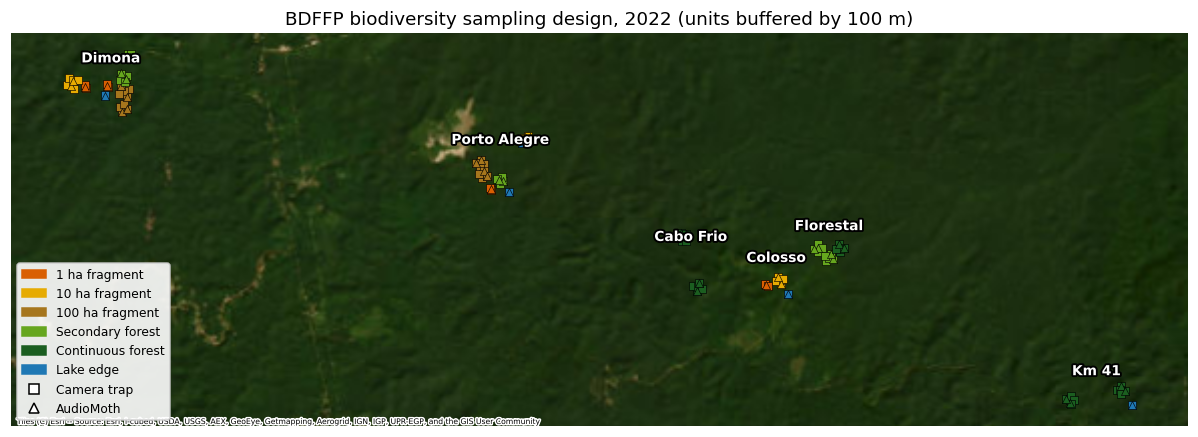

Saved device table for Demo 3: /content/drive/MyDrive/ARSET_GEDI_Biodiversity/devices.csv


In [ ]:
# Sampling-unit polygons: convex hull around each unit's devices, buffered by 100 m (as in Luther et al. 2026)
dev_gdf = gpd.GeoDataFrame(devices, geometry=gpd.points_from_xy(devices["lon"], devices["lat"]), crs="EPSG:4326")
utm = dev_gdf.estimate_utm_crs()
dev_gdf = dev_gdf.to_crs(utm)
units = (dev_gdf.dissolve(by=["unit_id", "reserve_name", "habitat"]).convex_hull.buffer(UNIT_BUFFER_M)
         .rename("geometry").reset_index())
units = gpd.GeoDataFrame(units, geometry="geometry", crs=utm)
units["area_ha"] = units.area / 1e4

w, s_, e, n = BBOX
outside = devices[~devices["lon"].between(w, e) | ~devices["lat"].between(s_, n)]
if len(outside):
    print(f"WARNING: {len(outside)} devices fall outside BBOX – enlarge BBOX in Section 2.")


def add_basemap(ax, zoom="auto"):
    try:
        import contextily as cx
        cx.add_basemap(ax, crs=utm, source=cx.providers.Esri.WorldImagery, attribution_size=5, zoom=zoom)
    except Exception:
        pass  # basemap is optional (needs internet access to tile servers)


# Study-design map
fig, ax = plt.subplots(figsize=(11, 5.5))
for h in HABITAT_ORDER:
    sel = units[units["habitat"] == h]
    if len(sel):
        sel.plot(ax=ax, color=HABITAT_COLORS[h], edgecolor="k", lw=0.5, alpha=0.85, label=HABITAT_LABELS[h])
for h in HABITAT_ORDER:   # devices colored by habitat (units are small at this map scale)
    for meth, mk in [("camera", "s"), ("audio", "^")]:
        sel = dev_gdf[(dev_gdf.habitat == h) & (dev_gdf.method == meth)]
        if len(sel):
            sel.plot(ax=ax, marker=mk, color=HABITAT_COLORS[h], edgecolor="k", markersize=28, lw=0.4)
import matplotlib.patheffects as pe
for name, g in dev_gdf.groupby("reserve_name"):
    c = g.geometry.union_all().centroid
    ax.annotate(name, (c.x, c.y), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=9,
                fontweight="bold", color="white", path_effects=[pe.withStroke(linewidth=2.5, foreground="black")])
add_basemap(ax)
handles = [plt.Rectangle((0, 0), 1, 1, color=HABITAT_COLORS[h]) for h in HABITAT_ORDER if h in set(units.habitat)]
handles += [plt.Line2D([], [], marker="s", ls="", mfc="white", mec="k", label="Camera trap"),
            plt.Line2D([], [], marker="^", ls="", mfc="white", mec="k", label="AudioMoth")]
labels = [HABITAT_LABELS[h] for h in HABITAT_ORDER if h in set(units.habitat)] + ["Camera trap", "AudioMoth"]
ax.legend(handles, labels, loc="lower left", fontsize=8, framealpha=0.9)
ax.set_title("BDFFP biodiversity sampling design, 2022 (units buffered by 100 m)")
ax.set_axis_off()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "bdffp_sampling_design.png"), dpi=200, bbox_inches="tight")
plt.show()

# Device table in the format Demo 3 expects
devices[["device_id", "unit_id", "reserve", "reserve_name", "habitat", "method", "lon", "lat"]].to_csv(
    os.path.join(OUT_DIR, "devices.csv"), index=False)
print("Saved device table for Demo 3:", os.path.join(OUT_DIR, "devices.csv"))

## 4. Find and read GEDI L2A + L2B footprints

Each GEDI orbit produces matching L2A and L2B granules. We pair them by orbit number, read only the footprints inside the study area, and join L2A and L2B on the unique `shot_number`.

You need a free NASA Earthdata Login account: https://urs.earthdata.nasa.gov

**If something goes wrong**
- **`500 Internal Server Error` / `An Internal Error has occurred`**: NASA's search service (CMR) had a temporary problem. The notebook retries automatically and then queries CMR directly. If it still fails, wait a few minutes and re-run. Service status: https://status.earthdata.nasa.gov
- **`401` / login prompt keeps failing**: log in once at https://urs.earthdata.nasa.gov in a browser to confirm your password. In Colab, store credentials as Colab Secrets `EARTHDATA_USERNAME` and `EARTHDATA_PASSWORD` (key icon, left sidebar; turn on notebook access).
- **Why is it slow?** The notebook already reads only the ~20 variables it needs, and only for shots inside the study area. Most of the time goes into opening each remote file and scanning the full-length latitude/longitude arrays of all 8 beams to find those shots. Each granule covers a long orbit segment, whatever the study area size. To speed this up, granules are read in parallel (`N_WORKERS`), L2B reuses the shot positions found in L2A, and remote files are read in large cached blocks. Expect roughly 15–30 minutes for the 61 orbit pairs of the Luther et al. period. Run it once, then use the saved table.
- **Interrupted run** (Colab disconnects, browser closed): just re-run. Every finished orbit is saved in `gedi_orbits_v003/`, so only the remaining orbits are read.
- **Streaming errors part-way through**: each granule is retried, and failed ones are skipped. The search results are saved (`bdffp_gedi_granule_links_*.json`), so re-running skips the search. Delete that file to search again.

In [ ]:
BEAMS = ["BEAM0000", "BEAM0001", "BEAM0010", "BEAM0011", "BEAM0101", "BEAM0110", "BEAM1000", "BEAM1011"]
POWER_BEAMS = {"BEAM0101", "BEAM0110", "BEAM1000", "BEAM1011"}
ORBIT_RE = re.compile(r"_O(\d{5})_(\d{2})_")


def orbit_key(name):
    """'..._O01994_02_...' -> '01994_02' (orbit + sub-orbit granule), used to pair L2A with L2B."""
    m = ORBIT_RE.search(os.path.basename(name))
    return f"{m.group(1)}_{m.group(2)}" if m else None


def with_retries(fn, what, tries=5, wait=10):
    """Run fn(); on failure wait and retry (NASA's search/data servers sometimes return temporary 5xx errors)."""
    for attempt in range(1, tries + 1):
        try:
            return fn()
        except Exception as err:
            if attempt == tries:
                raise
            print(f"  {what} failed (attempt {attempt}/{tries}: {str(err)[:120]}). Retrying in {wait} s ...")
            time.sleep(wait)
            wait = min(wait * 2, 120)


_LOGGED_IN = False


def earthdata_login():
    """Log in once per session. Uses Colab Secrets / environment variables if set, otherwise prompts."""
    global _LOGGED_IN
    if _LOGGED_IN:
        return
    import earthaccess
    if IN_COLAB:
        try:
            from google.colab import userdata
            for key in ("EARTHDATA_USERNAME", "EARTHDATA_PASSWORD"):
                os.environ.setdefault(key, userdata.get(key))
        except Exception:
            pass  # no Colab Secrets set (or notebook access not granted): fall back to the prompt
    use_env = bool(os.environ.get("EARTHDATA_USERNAME") and os.environ.get("EARTHDATA_PASSWORD"))
    auth = earthaccess.login(strategy="environment" if use_env else "interactive", persist=not use_env)
    if not getattr(auth, "authenticated", False):
        raise RuntimeError("Earthdata Login failed. Check your username/password at https://urs.earthdata.nasa.gov "
                           "(log in there once in a browser), then re-run this cell.")
    _LOGGED_IN = True
    print("Logged in to NASA Earthdata")


def cmr_granule_links(short_name, version):
    """Search NASA's CMR catalog for .h5 granule links. Uses earthaccess; falls back to the CMR API directly."""
    import earthaccess
    search = dict(short_name=short_name, bounding_box=BBOX, temporal=TEMPORAL)
    if version:
        search["version"] = version
    try:
        results = with_retries(lambda: earthaccess.search_data(**search), f"{short_name} search", tries=3)
        return [r.data_links(access="external")[0] for r in results if r.data_links(access="external")]
    except Exception as err:
        print(f"  earthaccess search for {short_name} failed ({str(err)[:100]}); querying CMR directly ...")
    import requests
    params = {"short_name": short_name, "bounding_box": ",".join(map(str, BBOX)), "page_size": 2000,
              "temporal[]": f"{TEMPORAL[0]}T00:00:00Z,{TEMPORAL[1]}T23:59:59Z"}
    if version:
        params["version"] = version
    links, headers = [], {}
    while True:
        r = with_retries(lambda: _cmr_get(params, headers), f"CMR {short_name} page")
        entries = r.json()["feed"]["entry"]
        for e in entries:
            hrefs = [l["href"] for l in e.get("links", []) if l.get("href", "").startswith("https")
                     and l["href"].endswith(".h5")]
            if hrefs:
                links.append(hrefs[0])
        after = r.headers.get("CMR-Search-After")
        if not entries or not after:
            return links
        headers["CMR-Search-After"] = after


def _cmr_get(params, headers):
    import requests
    r = requests.get("https://cmr.earthdata.nasa.gov/search/granules.json", params=params,
                     headers=headers, timeout=120)
    r.raise_for_status()
    return r


def find_granules():
    """Return a list of (orbit, L2A file, L2B file, L4A file or None); files are local paths or https links."""
    if LOCAL_GRANULE_DIR:
        files = sorted(glob.glob(os.path.join(LOCAL_GRANULE_DIR, "*.h5")))
        l2a = {orbit_key(f): f for f in files if "GEDI02_A" in os.path.basename(f)}
        l2b = {orbit_key(f): f for f in files if "GEDI02_B" in os.path.basename(f)}
        l4a = {orbit_key(f): f for f in files if "GEDI04_A" in os.path.basename(f)}
    else:
        earthdata_login()
        if USE_CACHE and os.path.exists(LINKS_FILE):   # skip the search if links were saved earlier
            with open(LINKS_FILE) as fh:
                saved = json.load(fh)
            l2a, l2b, l4a = saved["l2a"], saved["l2b"], saved.get("l4a", {})
            print(f"Loaded {len(l2a)} L2A and {len(l2b)} L2B granule links from {LINKS_FILE}")
        else:
            links_a = cmr_granule_links("GEDI02_A", GEDI_VERSION)
            links_b = cmr_granule_links("GEDI02_B", GEDI_VERSION)
            print(f"Found {len(links_a)} L2A and {len(links_b)} L2B granules")
            l2a = {orbit_key(u): u for u in links_a}
            l2b = {orbit_key(u): u for u in links_b}
            l4a = {}
            if INCLUDE_L4A:
                links_4 = cmr_granule_links(L4A_SHORT_NAME, None)
                print(f"Found {len(links_4)} L4A granules")
                l4a = {orbit_key(u): u for u in links_4}
            with open(LINKS_FILE, "w") as fh:
                json.dump({"l2a": l2a, "l2b": l2b, "l4a": l4a}, fh)
    keys = sorted(set(l2a) & set(l2b))
    if MAX_GRANULE_PAIRS:
        keys = keys[:MAX_GRANULE_PAIRS]
    return [(k, l2a[k], l2b[k], l4a.get(k)) for k in keys]


def open_h5(item):
    """Open a local file, or stream a granule over https with your Earthdata Login (retrying temporary errors)."""
    if os.path.exists(str(item)):
        return h5py.File(item, "r")
    import earthaccess
    earthdata_login()

    def _open():
        try:
            # Large cached blocks = far fewer small HTTP requests when h5py jumps around the file
            fs = earthaccess.get_fsspec_https_session()
            fobj = fs.open(item, mode="rb", cache_type="blockcache", block_size=8 * 2**20)
        except Exception:
            try:
                fobj = earthaccess.open([item], show_progress=False)[0]
            except TypeError:  # older earthaccess versions have no show_progress option
                fobj = earthaccess.open([item])[0]
        return h5py.File(fobj, "r")
    return with_retries(_open, f"opening {os.path.basename(str(item))}", tries=3)


# Variable paths differ between GEDI Version 2 and Version 3, so each variable lists its
# candidate paths (V3 name first, then V2). The first one found in the file is used.
#   - V3 renamed the quality flags: L2A quality_flag -> l2a_quality_flag_rel3,
#     L2B l2b_quality_flag -> l2b_quality_flag_rel3 (the V2-era flags are kept as *_rel2)
#   - V3 L2B keeps lat/lon/shot_number/degrade_flag at the beam root; V2 had them under geolocation/
L2A_VARS = {
    "lat": ["lat_lowestmode", "geolocation/lat_lowestmode"],
    "lon": ["lon_lowestmode", "geolocation/lon_lowestmode"],
    "shot_number": ["shot_number", "geolocation/shot_number"],
    "delta_time": ["delta_time", "geolocation/delta_time"],
    "quality_flag": ["l2a_quality_flag_rel3", "quality_flag"],
    "degrade_flag": ["degrade_flag", "geolocation/degrade_flag"],
    "sensitivity": ["sensitivity", "geolocation/sensitivity"],
    "elev_ground": ["elev_lowestmode", "geolocation/elev_lowestmode"],
    "rh": ["rh"],
}
L2A_OPTIONAL = {"quality_flag_rel2": ["l2a_quality_flag_rel2", "geolocation/l2a_quality_flag_rel2"]}

L2B_VARS = {
    "lat": ["lat_lowestmode", "geolocation/lat_lowestmode"],
    "lon": ["lon_lowestmode", "geolocation/lon_lowestmode"],
    "shot_number": ["shot_number", "geolocation/shot_number"],
    "l2b_quality_flag": ["l2b_quality_flag_rel3", "l2b_quality_flag"],
    "l2b_degrade_flag": ["degrade_flag", "geolocation/degrade_flag"],
    "cover": ["cover"], "pai": ["pai"], "fhd_normal": ["fhd_normal"],
    "pavd_z": ["pavd_z"], "pai_z": ["pai_z"], "cover_z": ["cover_z"],
}
L2B_OPTIONAL = {"l2b_quality_flag_rel2": ["l2b_quality_flag_rel2", "geolocation/l2b_quality_flag_rel2"]}


def resolve(grp, name, candidates):
    """Return the first candidate path present in this beam group, or explain what the file contains."""
    for p in candidates:
        if p in grp:
            return p
    flags = []
    grp.visit(lambda k: flags.append(k) if ("flag" in k or "lowestmode" in k) else None)
    raise KeyError(f"'{name}' not found in {grp.file.filename}:{grp.name} (tried {candidates}). "
                   f"Flag/location variables in this beam: {sorted(flags)}")


def _bbox_slice(lat, lon):
    """Indices of shots inside BBOX, plus the contiguous slice that covers them (fast partial reads)."""
    w, s, e, n = BBOX
    inside = np.where((lon >= w) & (lon <= e) & (lat >= s) & (lat <= n))[0]
    if inside.size == 0:
        return None, None
    return slice(inside[0], inside[-1] + 1), inside - inside[0]


def read_vars(g, spec, optional, sl, idx):
    out = {}
    for name, cands in spec.items():
        if name in ("lat", "lon"):
            continue
        out[name] = g[resolve(g, name, cands)][sl][idx]
    for name, cands in optional.items():
        path = next((p for p in cands if p in g), None)
        if path:
            out[name] = g[path][sl][idx]
    return out


def read_l2a(f, beam):
    g = f[beam]
    lat = g[resolve(g, "lat", L2A_VARS["lat"])][:]   # the only full-length arrays we read
    lon = g[resolve(g, "lon", L2A_VARS["lon"])][:]
    sl, idx = _bbox_slice(lat, lon)
    if sl is None:
        return None
    v = read_vars(g, L2A_VARS, L2A_OPTIONAL, sl, idx)
    rh = v.pop("rh")
    df = pd.DataFrame({"beam": beam, "lat": lat[sl][idx], "lon": lon[sl][idx], **v})
    df["shot_number"] = df["shot_number"].astype("uint64")
    for q in (50, 95, 98, 100):
        df[f"RH{q}"] = rh[:, q]
    df.attrs["slice"] = (sl, idx)
    return df


def read_l2b(f, beam, l2a=None):
    """Read L2B for the study-area shots. L2B is derived shot-by-shot from L2A, so we reuse L2A's
    positions (checked via shot_number) instead of reading L2B's full-length lat/lon arrays again."""
    g = f[beam]
    sl = None
    if l2a is not None and "slice" in l2a.attrs:
        sl, idx = l2a.attrs["slice"]
        shots_b = g[resolve(g, "shot_number", L2B_VARS["shot_number"])][sl]
        if len(shots_b) != sl.stop - sl.start or not np.array_equal(
                shots_b[idx].astype("uint64"), l2a["shot_number"].values):
            sl = None   # shots not aligned in this file: fall back to locating them by lat/lon
    if sl is None:
        lat = g[resolve(g, "lat", L2B_VARS["lat"])][:]
        lon = g[resolve(g, "lon", L2B_VARS["lon"])][:]
        sl, idx = _bbox_slice(lat, lon)
        if sl is None:
            return None
    v = read_vars(g, L2B_VARS, L2B_OPTIONAL, sl, idx)
    # Vertical profiles in 5 m bins (bin i = i*5 to i*5+5 m above ground), stored as arrays per footprint
    profiles = {k: list(v.pop(k).astype("float32")) for k in ["pavd_z", "pai_z", "cover_z"]}
    df = pd.DataFrame({**v, **profiles})
    df["shot_number"] = df["shot_number"].astype("uint64")
    return df


def read_l4a(f, beam):
    g = f[beam]
    sl, idx = _bbox_slice(g["lat_lowestmode"][:], g["lon_lowestmode"][:])
    if sl is None:
        return None
    return pd.DataFrame({"shot_number": g["shot_number"][sl][idx].astype("uint64"),
                         "AGBD": g["agbd"][sl][idx],
                         "l4_quality_flag": g["l4_quality_flag"][sl][idx]})


def describe_layout(item, label):
    """Print which quality/degrade/location variables a GEDI file contains (V2 vs V3 check)."""
    with open_h5(item) as f:
        beam = next(b for b in BEAMS if b in f)
        g = f[beam]
        names = []
        g.visit(lambda k: names.append(k) if ("flag" in k or "lowestmode" in k) else None)
        print(f"{label} ({beam}): " + ", ".join(sorted(names)))


def _read_orbit(ga, gb, g4, key):
    fa, fb = open_h5(ga), open_h5(gb)
    f4 = open_h5(g4) if (INCLUDE_L4A and g4 is not None) else None
    frames = []
    try:
        for beam in BEAMS:
            if beam not in fa or beam not in fb:
                continue
            a = read_l2a(fa, beam)
            if a is None:
                continue
            b = read_l2b(fb, beam, l2a=a)
            if b is None:
                continue
            a.attrs = {}
            df = a.merge(b, on="shot_number", how="inner")
            if f4 is not None and beam in f4:
                d4 = read_l4a(f4, beam)
                if d4 is not None:
                    df = df.merge(d4, on="shot_number", how="left")
            df["orbit"] = key
            frames.append(df)
    finally:
        for fh in (fa, fb, f4):
            if fh is not None:
                fh.close()
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame({"orbit": pd.Series(dtype=str)})


def read_pair(task, tries=3):
    """Read one orbit's L2A + L2B (+ L4A) footprints inside BBOX and save a per-orbit checkpoint file,
    so an interrupted run (Colab disconnect, server error) resumes where it stopped."""
    key, ga, gb, g4 = task
    ckpt = os.path.join(CHUNK_DIR, f"{key}.parquet")
    if os.path.exists(ckpt):
        return key, pd.read_parquet(ckpt), "checkpoint"
    wait = 15
    for attempt in range(1, tries + 1):
        try:
            out = _read_orbit(ga, gb, g4, key)
            out.to_parquet(ckpt)
            return key, out, "read"
        except KeyError:
            raise          # a variable is missing: a real problem, stop with details
        except Exception as err:  # temporary server/network errors (e.g. 502 Bad Gateway): wait and retry
            if attempt == tries:
                return key, None, f"FAILED after {tries} tries ({str(err)[:120]})"
            time.sleep(wait)
            wait *= 2


def _worker_init():
    """Each worker process opens its own fresh connections to NASA (sockets can't be shared across processes)."""
    global _LOGGED_IN
    _LOGGED_IN = False
    if not LOCAL_GRANULE_DIR:
        import earthaccess
        use_env = bool(os.environ.get("EARTHDATA_USERNAME") and os.environ.get("EARTHDATA_PASSWORD"))
        earthaccess.login(strategy="environment" if use_env else "netrc")
        _LOGGED_IN = True


def extract_footprints():
    pairs = find_granules()
    os.makedirs(CHUNK_DIR, exist_ok=True)
    done = sum(os.path.exists(os.path.join(CHUNK_DIR, f"{k}.parquet")) for k, *_ in pairs)
    print(f"Reading {len(pairs)} matched L2A/L2B granule pairs ({done} already saved from an earlier run), "
          f"{N_WORKERS} at a time ...")
    if pairs and SHOW_FILE_LAYOUT:
        describe_layout(pairs[0][1], "L2A variables")
        describe_layout(pairs[0][2], "L2B variables")
    t0, frames, n, failed = time.time(), [], 0, []

    def report(i, key, df, status):
        nonlocal n
        if df is None:
            failed.append(key)
        if df is not None and len(df):
            frames.append(df)
            n += len(df)
        mins = (time.time() - t0) / 60
        print(f"  [{i}/{len(pairs)}] orbit {key}: {status}; {n:,} footprints so far ({mins:.1f} min)")

    if N_WORKERS > 1 and len(pairs) > 1:
        import multiprocessing as mp
        from concurrent.futures import ProcessPoolExecutor, as_completed
        with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context("fork"), initializer=_worker_init) as ex:
            futures = [ex.submit(read_pair, t) for t in pairs]
            for i, fut in enumerate(as_completed(futures), 1):
                report(i, *fut.result())
    else:
        for i, t in enumerate(pairs, 1):
            report(i, *read_pair(t))
    if failed:
        raise RuntimeError(f"{len(failed)} orbit(s) could not be read ({', '.join(failed)}), usually a temporary "
                           "NASA server error. Re-run this cell: finished orbits are kept, only these are retried.")
    if not frames:
        raise RuntimeError("No GEDI footprints found inside BBOX for the selected dates.")
    return pd.concat(frames, ignore_index=True).sort_values(["orbit", "beam", "shot_number"]).reset_index(drop=True)

In [ ]:
if USE_CACHE and os.path.exists(CACHE_FILE):
    shots = pd.read_parquet(CACHE_FILE)
    for var in ["pavd_z", "pai_z", "cover_z"]:
        shots[var] = shots[var].apply(np.asarray)
    print(f"Loaded {len(shots):,} cached footprints from {CACHE_FILE}")
else:
    shots = extract_footprints()
    if SAVE_CACHE:
        shots.to_parquet(CACHE_FILE)
        print(f"Saved {len(shots):,} footprints to {CACHE_FILE}")

shots.head()

Enter your Earthdata Login username: sc4751@columbia.edu
Enter your Earthdata password: ··········
Logged in to NASA Earthdata
Found 61 L2A and 61 L2B granules
Reading 61 matched L2A/L2B granule pairs (45 already saved from an earlier run), 4 at a time ...
  [1/61] orbit 02179_01: checkpoint; 2,142 footprints so far (0.0 min)
  [2/61] orbit 02171_04: checkpoint; 4,855 footprints so far (0.0 min)
  [3/61] orbit 02072_01: checkpoint; 9,561 footprints so far (0.0 min)
  [4/61] orbit 02064_04: checkpoint; 14,243 footprints so far (0.0 min)
  [5/61] orbit 03752_01: checkpoint; 14,243 footprints so far (0.0 min)
  [6/61] orbit 03286_04: checkpoint; 14,243 footprints so far (0.0 min)
  [7/61] orbit 02721_04: checkpoint; 14,568 footprints so far (0.0 min)
  [8/61] orbit 02729_01: checkpoint; 19,269 footprints so far (0.0 min)
  [9/61] orbit 04332_01: checkpoint; 23,985 footprints so far (0.0 min)
  [10/61] orbit 04675_04: checkpoint; 28,263 footprints so far (0.0 min)
  [11/61] orbit 05095_01:

,beam,lat,lon,shot_number,delta_time,quality_flag,degrade_flag,sensitivity,elev_ground,quality_flag_rel2,RH50,RH95,RH98,RH100,l2b_quality_flag,l2b_degrade_flag,cover,pai,fhd_normal,l2b_quality_flag_rel2,pavd_z,pai_z,cover_z,orbit
0,BEAM0000,-2.250284,-59.871717,20640000400284476,4.137014e+07,0,0,0.927104,70.737831,0,2.69,5.13,5.31,5.46,0,0,-9999.000000,-9999.000000,-9999.000000,0,"[-9999.0, -9999.0, -9999.0, -9999.0, -9999.0, ...","[-9999.0, -9999.0, -9999.0, -9999.0, -9999.0, ...","[-9999.0, -9999.0, -9999.0, -9999.0, -9999.0, ...",02064_04
1,BEAM0000,-2.250706,-59.871423,20640000400284477,4.137014e+07,0,0,-0.331816,91.172104,0,0.00,0.00,0.00,0.00,0,0,-9999.000000,-9999.000000,-9999.000000,0,"[-9999.0, -9999.0, -9999.0, -9999.0, -9999.0, ...","[-9999.0, -9999.0, -9999.0, -9999.0, -9999.0, ...","[-9999.0, -9999.0, -9999.0, -9999.0, -9999.0, ...",02064_04
2,BEAM0000,-2.251132,-59.871124,20640000400284478,4.137014e+07,0,0,0.875793,64.123482,0,3.93,7.45,7.75,7.97,0,0,-9999.000000,-9999.000000,-9999.000000,0,"[-9999.0, -9999.0, -9999.0, -9999.0, -9999.0, ...","[-9999.0, -9999.0, -9999.0, -9999.0, -9999.0, ...","[-9999.0, -9999.0, -9999.0, -9999.0, -9999.0, ...",02064_04
3,BEAM0000,-2.251556,-59.870827,20640000400284479,4.137014e+07,0,0,0.932830,61.112469,1,5.09,9.25,9.77,10.22,0,0,0.806635,3.286898,2.201141,1,"[0.37283564, 0.3234231, 0.14227195, 0.00526667...","[3.2868977, 1.4227195, 0.052666765, -0.0, -0.0...","[0.8066346, 0.5090065, 0.025989646, 0.0, 0.0, ...",02064_04
4,BEAM0000,-2.251980,-59.870531,20640000400284480,4.137014e+07,0,0,0.951275,60.643585,1,4.53,8.09,8.61,9.06,0,0,0.700230,2.409728,2.107842,1,"[0.24076058, 0.2409728, 0.12059252, -0.0, -0.0...","[2.409728, 1.2059252, -0.0, -0.0, -0.0, -0.0, ...","[0.70023036, 0.4527985, 0.0, 0.0, 0.0, 0.0, 0....",02064_04


## 5. Quality filtering

Standard GEDI L2 filtering keeps footprints with **`quality_flag == 1` AND `degrade_flag == 0`**. The quality flag combines energy, sensitivity, amplitude and surface-tracking checks. The degrade flag marks shots taken while the ISS pointing or positioning information was degraded. Following Luther et al. (2026), we apply this to both L2A and L2B and also require adequate beam sensitivity.

**Version note:** in GEDI Version 3 the quality flags were renamed (`l2a_quality_flag_rel3`, `l2b_quality_flag_rel3`), and the V3 definition is stricter. The V2-era flags (`*_rel2`) are kept in the files. The reader in Section 4 maps whichever name the file uses to `quality_flag` / `l2b_quality_flag`, so this filter works for both versions.

In [ ]:
qc = (
    (shots["quality_flag"] == 1)            # L2A quality (l2a_quality_flag_rel3 in V3)
    & (shots["l2b_quality_flag"] == 1)      # L2B quality (l2b_quality_flag_rel3 in V3)
    & (shots["degrade_flag"] == 0)          # no degraded pointing/positioning (L2A)
    & (shots["l2b_degrade_flag"] == 0)      # ... and in L2B
    & (shots["sensitivity"] >= MIN_SENSITIVITY)
)
if POWER_BEAMS_ONLY:
    qc &= shots["beam"].isin(POWER_BEAMS)
if "AGBD" in shots:
    shots.loc[shots["l4_quality_flag"] != 1, "AGBD"] = np.nan

good = shots[qc].copy().reset_index(drop=True)
print(f"All footprints in study area: {len(shots):,}")
print(f"Good-quality footprints:      {len(good):,} ({len(good) / len(shots):.0%})")
print(f"Orbits contributing:          {good['orbit'].nunique()}")
print("\nShots removed by each criterion (not mutually exclusive):")
print(f"  L2A quality flag != 1:  {(shots['quality_flag'] != 1).sum():,}")
print(f"  L2B quality flag != 1:  {(shots['l2b_quality_flag'] != 1).sum():,}")
print(f"  degrade flag != 0:      {((shots['degrade_flag'] != 0) | (shots['l2b_degrade_flag'] != 0)).sum():,}")
print(f"  sensitivity < {MIN_SENSITIVITY}:    {(shots['sensitivity'] < MIN_SENSITIVITY).sum():,}")
if "quality_flag_rel2" in shots:   # V3 files only: compare the new and V2-era L2A quality definitions
    print(f"\nV3 vs V2-era L2A quality flag: {(shots['quality_flag'] == 1).sum():,} shots pass rel3, "
          f"{(shots['quality_flag_rel2'] == 1).sum():,} pass rel2")

All footprints in study area: 187,088
Good-quality footprints:      21,839 (12%)
Orbits contributing:          32

Shots removed by each criterion (not mutually exclusive):
  L2A quality flag != 1:  155,251
  L2B quality flag != 1:  155,263
  degrade flag != 0:      37,709
  sensitivity < 0.98:    104,298

V3 vs V2-era L2A quality flag: 31,837 shots pass rel3, 80,726 pass rel2


## 6. Footprint-level structure metrics

| Metric | Source | What it tells us |
|---|---|---|
| **RH98 / RH95** | L2A | Canopy top height (m) |
| **PAI** | L2B | Total plant area per unit ground area |
| **FHD** | L2B `fhd_normal` | How evenly foliage is spread across heights (vertical heterogeneity) |
| **FHD (recomputed)** | from L2B `pavd_z` | Same idea, calculated by us: Shannon index of the normalized 5 m PAVD profile |
| **PAVD_count** | from `pavd_z` | Number of local maxima in the profile ≈ number of canopy layers |
| **PAVD / PAI / Cover ratio** | from profiles | Overstory vs. understory: > 1 = most plant material in the upper half of the canopy |

$$FHD = -\sum_i p_i \ln p_i, \qquad p_i = \frac{PAVD_i}{\sum_j PAVD_j}$$

In [ ]:
DZ = 5.0  # GEDI L2B profile bin size (m)


def fhd_from_profile(pavd):
    p = np.clip(np.asarray(pavd, dtype=float), 0, None)
    if p.sum() <= 0:
        return np.nan
    p = p[p > 0] / p.sum()
    return float(-(p * np.log(p)).sum())


def n_layers(pavd, min_prominence=0.002):
    """Count local maxima in the PAVD profile (Luther et al.'s GEDI_PAVD_count)."""
    p = np.clip(np.asarray(pavd, dtype=float), 0, None)
    if p.sum() <= 0:
        return 0
    peaks, _ = find_peaks(np.r_[0, p, 0], prominence=min_prominence)
    return int(len(peaks))


def layer_amounts(cumulative):
    """Convert a cumulative-from-top profile (pai_z, cover_z) into per-bin amounts."""
    c = np.clip(np.asarray(cumulative, dtype=float), 0, None)
    return np.clip(c - np.r_[c[1:], 0], 0, None)


def top_bottom_ratio(layers, canopy_height):
    """Sum of the upper half of canopy bins divided by the lower half (bins up to canopy height)."""
    n = int(np.clip(np.ceil(canopy_height / DZ), 2, len(layers)))
    half = n // 2
    bottom, top = layers[:half].sum(), layers[half:n].sum()
    # undefined when the lower canopy is (almost) empty: avoids extreme ratios dominating unit means
    return float(top / bottom) if bottom > 0.01 * (top + bottom) and bottom > 0 else np.nan


rows = []
for pavd, paiz, coverz, h in zip(good["pavd_z"], good["pai_z"], good["cover_z"], good["RH98"]):
    pavd = np.clip(pavd, 0, None)
    rows.append({
        "FHD_recalc": fhd_from_profile(pavd),
        "PAVD_count": n_layers(pavd),
        "PAVD_total": float(pavd.sum() * DZ),
        "PAVD_5m": float(pavd[1]),    # 5–10 m bin
        "PAVD_15m": float(pavd[3]),   # 15–20 m bin
        "PAVD_25m": float(pavd[5]),   # 25–30 m bin
        "PAVD_ratio": top_bottom_ratio(pavd, h),
        "PAI_ratio": top_bottom_ratio(layer_amounts(paiz), h),
        "Cover_ratio": top_bottom_ratio(layer_amounts(coverz), h),
    })
good = pd.concat([good, pd.DataFrame(rows)], axis=1)
good = good.rename(columns={"fhd_normal": "FHD", "pai": "PAI_total", "cover": "Cover_total"})

metrics = ["RH95", "RH98", "PAI_total", "Cover_total", "FHD", "FHD_recalc", "PAVD_count",
           "PAVD_total", "PAVD_ratio", "PAI_ratio", "Cover_ratio"] + (["AGBD"] if "AGBD" in good else [])
good[metrics].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
RH95,21839.0,27.88,7.40,1.91,24.22,27.61,31.03,131.94
RH98,21839.0,29.41,7.77,2.36,25.57,29.08,32.68,135.57
PAI_total,21839.0,5.25,1.36,0.01,4.68,5.30,5.78,10.96
Cover_total,21839.0,0.91,0.10,0.00,0.90,0.93,0.94,1.00
FHD,21839.0,3.23,0.26,0.65,3.12,3.26,3.38,4.44
FHD_recalc,21839.0,1.80,0.20,0.64,1.70,1.82,1.93,2.96
PAVD_count,21839.0,1.21,0.43,0.00,1.00,1.00,1.00,5.00
PAVD_total,21839.0,5.59,1.47,0.01,4.94,5.59,6.13,12.47
PAVD_ratio,21839.0,1.35,0.86,0.01,0.81,1.16,1.64,21.76
PAI_ratio,21839.0,1.01,0.67,0.00,0.60,0.89,1.26,28.30


### What does FHD look like?
The three footprints below have low, medium and high FHD. Higher FHD = plant material spread across more height layers = more potential niches (the habitat heterogeneity hypothesis from Part 1).

The right panel compares the L2B product with our recomputed FHD. The two may differ in absolute value, because the L2B algorithm works with a finer vertical profile than the 5 m `pavd_z` bins. What matters is that they rank footprints the same way (high correlation).

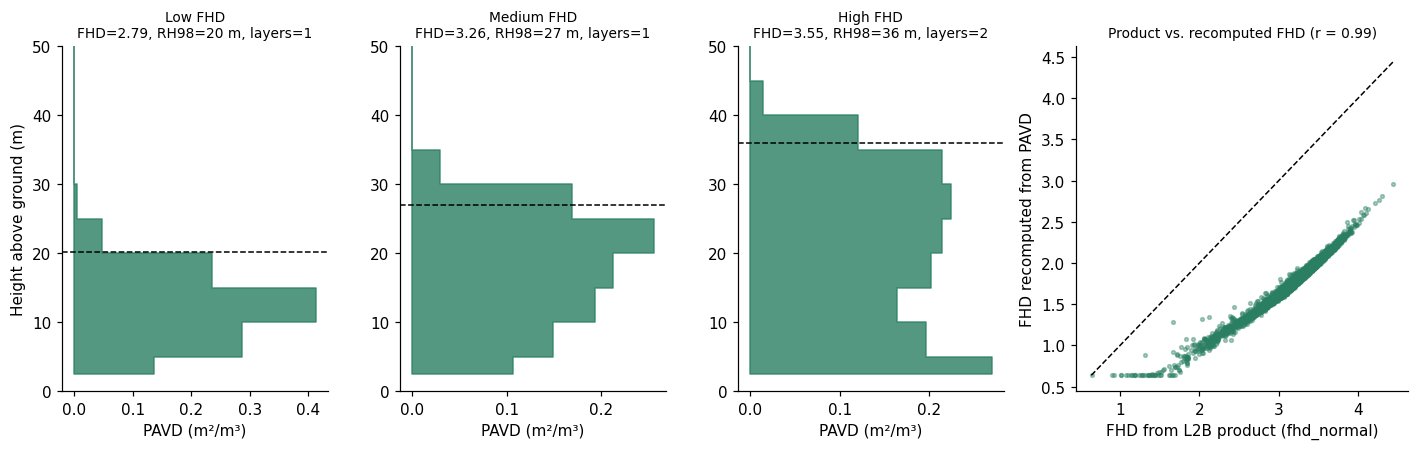

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.25]})
qs = good["FHD"].quantile([0.05, 0.5, 0.95]).values
labels = ["Low FHD", "Medium FHD", "High FHD"]
heights = np.arange(len(good["pavd_z"].iloc[0])) * DZ + DZ / 2
for ax, q, lab in zip(axes[:3], qs, labels):
    i = (good["FHD"] - q).abs().idxmin()
    r = good.loc[i]
    ax.fill_betweenx(heights, 0, r["pavd_z"], color="#2a7f62", alpha=0.8, step="mid")
    ax.axhline(r["RH98"], color="k", ls="--", lw=1)
    ax.set_ylim(0, 50)
    ax.set_title(f"{lab}\nFHD={r['FHD']:.2f}, RH98={r['RH98']:.0f} m, layers={r['PAVD_count']}", fontsize=9)
    ax.set_xlabel("PAVD (m²/m³)")
axes[0].set_ylabel("Height above ground (m)")

ax = axes[3]
ax.scatter(good["FHD"], good["FHD_recalc"], s=6, alpha=0.4, color="#2a7f62")
lims = [np.nanmin(good[["FHD", "FHD_recalc"]].values), np.nanmax(good[["FHD", "FHD_recalc"]].values)]
ax.plot(lims, lims, "k--", lw=1)
r = good[["FHD", "FHD_recalc"]].corr().iloc[0, 1]
ax.set_xlabel("FHD from L2B product (fhd_normal)")
ax.set_ylabel("FHD recomputed from PAVD")
ax.set_title(f"Product vs. recomputed FHD (r = {r:.2f})", fontsize=9)
plt.tight_layout()
plt.show()

## 7. Height diversity and vertical structure complexity maps

A single footprint describes **vertical** structure. **Height diversity** describes **horizontal** heterogeneity: how much canopy height varies among neighboring footprints. We grid the landscape and calculate, for each cell:
- mean canopy height (RH98)
- **height diversity** = standard deviation of RH98, plus a Shannon index of 5 m height classes
- mean FHD, PAI and number of canopy layers

In [ ]:
gdf = gpd.GeoDataFrame(good, geometry=gpd.points_from_xy(good["lon"], good["lat"]), crs="EPSG:4326").to_crs(utm)
gdf["cx"] = (gdf.geometry.x // GRID_SIZE_M).astype(int)
gdf["cy"] = (gdf.geometry.y // GRID_SIZE_M).astype(int)


def shannon_height_classes(h, width=5.0):
    counts = np.bincount((np.clip(h, 0, None) // width).astype(int))
    p = counts[counts > 0] / counts.sum()
    return float(-(p * np.log(p)).sum())


cells = gdf.groupby(["cx", "cy"]).agg(
    n=("RH98", "size"),
    RH98_mean=("RH98", "mean"),
    height_sd=("RH98", "std"),
    height_shannon=("RH98", shannon_height_classes),
    FHD_mean=("FHD", "mean"),
    PAI_mean=("PAI_total", "mean"),
    layers_mean=("PAVD_count", "mean"),
).reset_index()
cells = cells[cells["n"] >= MIN_SHOTS_PER_CELL]
cells = gpd.GeoDataFrame(
    cells,
    geometry=[box(x * GRID_SIZE_M, y * GRID_SIZE_M, (x + 1) * GRID_SIZE_M, (y + 1) * GRID_SIZE_M)
              for x, y in zip(cells["cx"], cells["cy"])],
    crs=utm,
)
print(f"{len(cells)} grid cells of {GRID_SIZE_M} m with ≥ {MIN_SHOTS_PER_CELL} good footprints")
cells.drop(columns="geometry").describe().T.round(2)

2064 grid cells of 500 m with ≥ 5 good footprints


,count,mean,std,min,25%,50%,75%,max
cx,2064.0,341.62,30.43,288.00,316.00,338.00,365.00,399.00
cy,2064.0,19471.45,16.82,19446.00,19456.00,19470.00,19486.25,19501.00
n,2064.0,8.49,3.27,5.00,6.00,8.00,10.00,30.00
RH98_mean,2064.0,29.52,4.82,8.69,27.39,29.60,31.84,73.53
height_sd,2064.0,5.38,3.54,0.84,3.45,4.57,6.20,37.27
height_shannon,2064.0,1.10,0.30,-0.00,0.95,1.08,1.32,2.08
FHD_mean,2064.0,3.23,0.16,2.09,3.18,3.26,3.33,3.61
PAI_mean,2064.0,5.27,0.61,1.43,4.99,5.31,5.62,7.77
layers_mean,2064.0,1.21,0.18,0.92,1.08,1.20,1.32,2.40


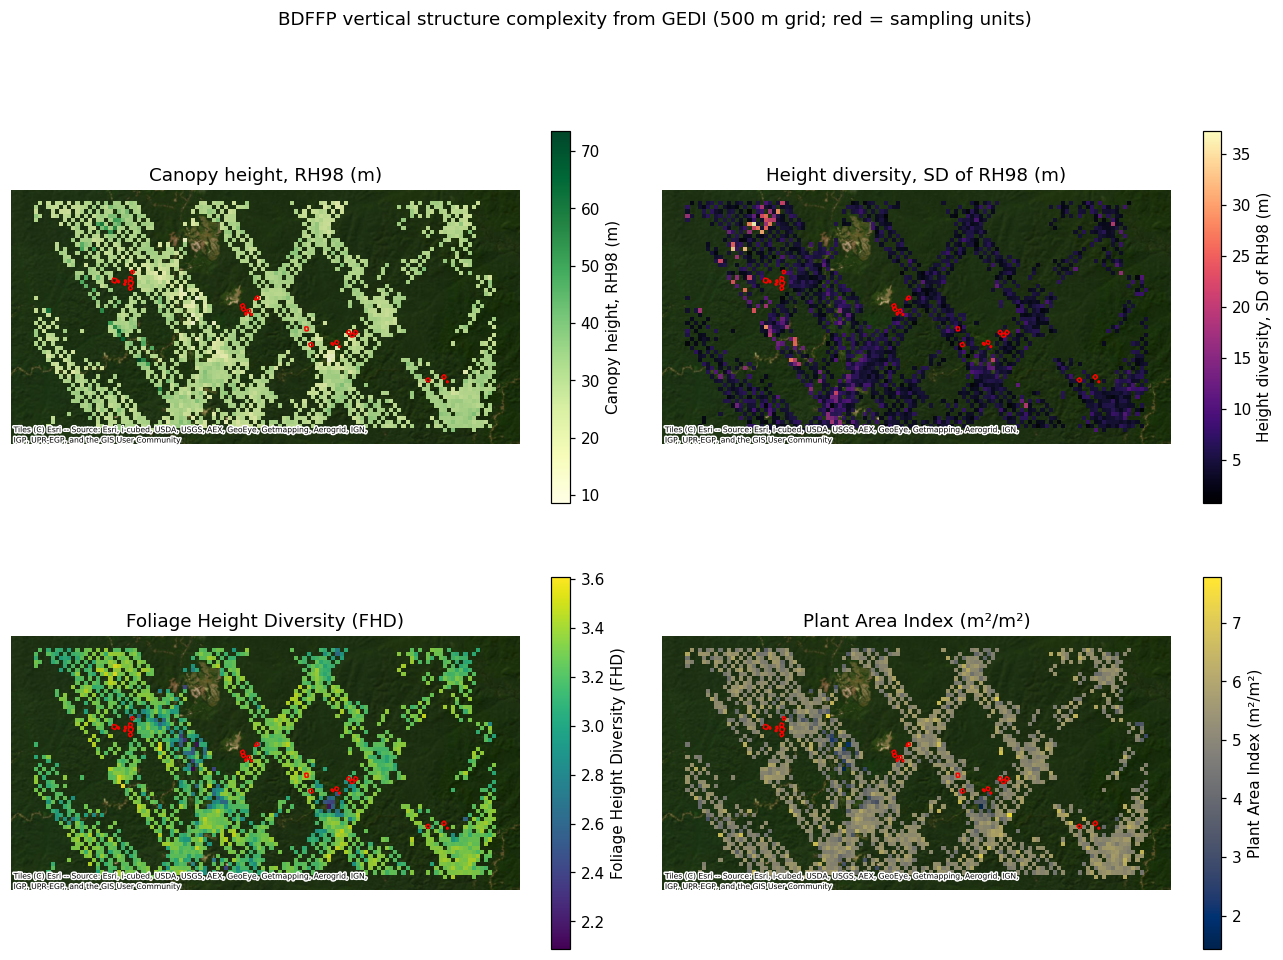

In [ ]:
panels = [("RH98_mean", "Canopy height, RH98 (m)", "YlGn"),
          ("height_sd", "Height diversity, SD of RH98 (m)", "magma"),
          ("FHD_mean", "Foliage Height Diversity (FHD)", "viridis"),
          ("PAI_mean", "Plant Area Index (m²/m²)", "cividis")]
fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))
for ax, (col, title, cmap) in zip(axes.ravel(), panels):
    cells.plot(column=col, cmap=cmap, legend=True, ax=ax, alpha=0.9,
               legend_kwds={"shrink": 0.7, "label": title})
    units.boundary.plot(ax=ax, color="red", lw=1)
    add_basemap(ax)
    ax.set_title(title)
    ax.set_axis_off()
fig.suptitle(f"BDFFP vertical structure complexity from GEDI ({GRID_SIZE_M} m grid; red = sampling units)", y=0.99)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "bdffp_structure_maps.png"), dpi=200, bbox_inches="tight")
plt.show()

## 8. Compare forest types: fragments, secondary forest and continuous mature forest

Following Luther et al. (2026), each sampling unit is the area around its cameras and recorders, buffered by 100 m (Section 3). We keep the GEDI footprints that fall inside each unit and average them per unit.

Luther et al. found that 18 of their 25 units overlapped good-quality GEDI footprints (117 footprints from 13 orbits, Apr 2019 – Jan 2023). Your counts will differ with GEDI Version 3, the date range and the quality filters.

In [ ]:
in_units = gpd.sjoin(gdf, units[["unit_id", "reserve_name", "habitat", "geometry"]], predicate="within", how="inner")
order = [h for h in HABITAT_ORDER if h in set(in_units["habitat"])]

coverage = (unit_table.set_index("unit_id")
            .join(in_units.groupby("unit_id").agg(n_footprints=("shot_number", "size"),
                                                  n_orbits=("orbit", "nunique")))
            .fillna({"n_footprints": 0, "n_orbits": 0}).astype({"n_footprints": int, "n_orbits": int}))
covered = coverage[coverage["n_footprints"] > 0]
print(f"{len(in_units):,} good footprints fall inside {len(covered)} of {len(coverage)} sampling units "
      f"(from {in_units['orbit'].nunique()} orbits)")
print("Units without GEDI coverage:", ", ".join(coverage.index[coverage["n_footprints"] == 0]) or "none")
coverage.sort_values(["habitat", "n_footprints"], ascending=[True, False])

40 good footprints fall inside 13 of 26 sampling units (from 8 orbits)
Units without GEDI coverage: CF-CFA, CO-10, CO-L, D-10, D-100B, D-L, D-SF1, KM41-CFA, PA-1, PA-100A, PA-100B, PA-L1, PA-L2


,reserve_name,habitat,cameras,recorders,n_footprints,n_orbits
unit_id,,,,,,
CO-1,Colosso,1ha,2,1,2,2
D-1A,Dimona,1ha,2,1,1,1
D-1B,Dimona,1ha,2,1,1,1
PA-1,Porto Alegre,1ha,2,1,0,0
PA-10,Porto Alegre,10ha,5,2,1,1
CO-10,Colosso,10ha,5,2,0,0
D-10,Dimona,10ha,5,2,0,0
D-100A,Dimona,100ha,5,2,1,1
D-100B,Dimona,100ha,5,2,0,0


### Footprint-level structure maps for each reserve
Zooming in on the six reserves shows exactly which footprints describe each sampling unit (colored by FHD).

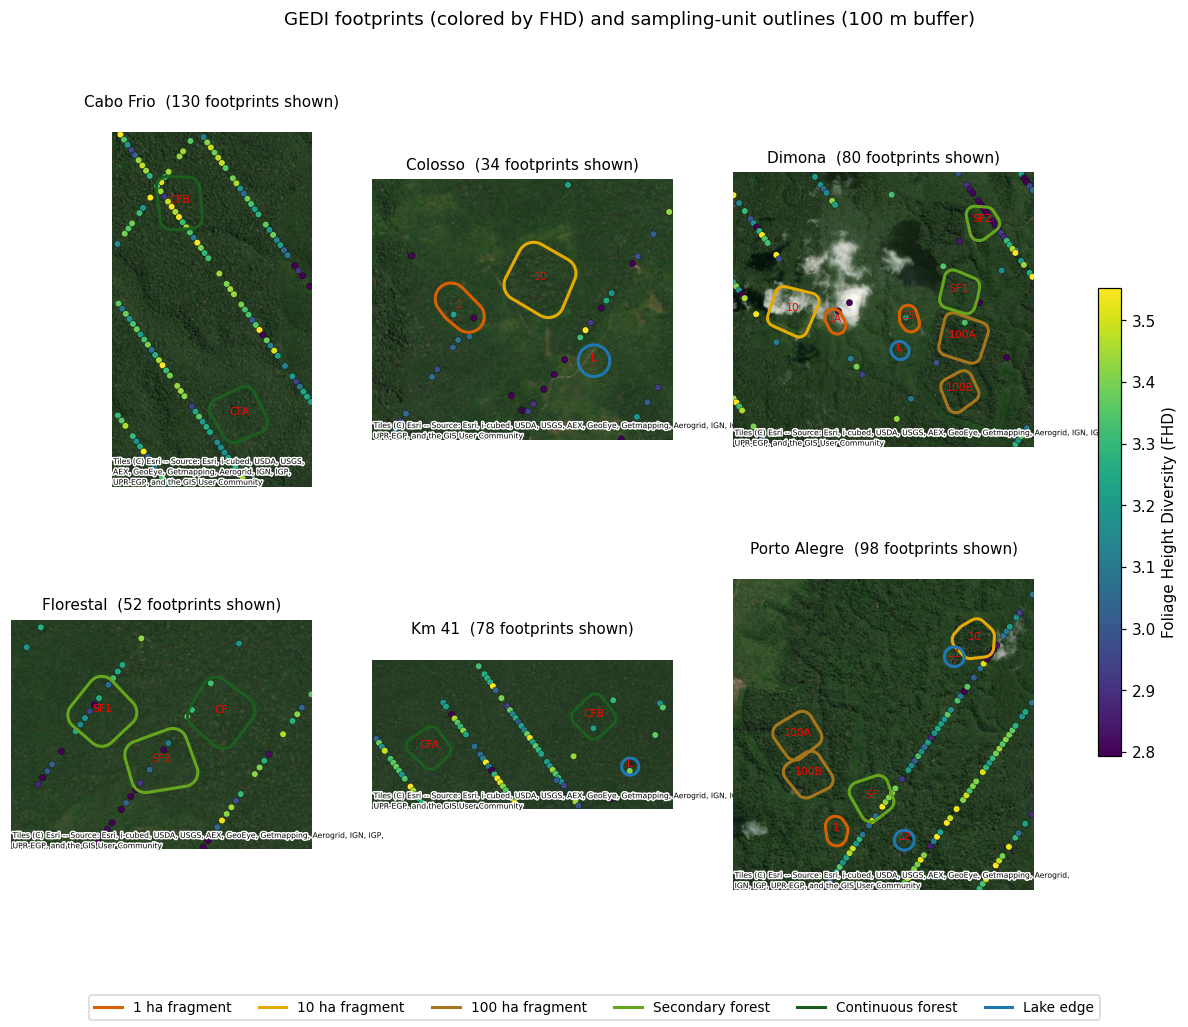

In [ ]:
reserves = sorted(units["reserve_name"].unique())
ncol = 3
nrow = int(np.ceil(len(reserves) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4.6 * nrow))
vmin, vmax = np.nanpercentile(gdf["FHD"], [5, 95])
for ax, rname in zip(axes.ravel(), reserves):
    u = units[units["reserve_name"] == rname]
    x0, y0, x1, y1 = u.total_bounds
    pad = 400
    near = gdf.cx[x0 - pad:x1 + pad, y0 - pad:y1 + pad]
    for h in HABITAT_ORDER:
        uh = u[u["habitat"] == h]
        if len(uh):
            uh.boundary.plot(ax=ax, color=HABITAT_COLORS[h], lw=2)
    if len(near):
        near.plot(ax=ax, column="FHD", cmap="viridis", vmin=vmin, vmax=vmax, markersize=18, edgecolor="k", lw=0.2)
    for _, r in u.iterrows():
        c = r.geometry.centroid
        ax.annotate(r["unit_id"].split("-", 1)[1], (c.x, c.y), fontsize=7, ha="center", color="red")
    ax.set_xlim(x0 - pad, x1 + pad)
    ax.set_ylim(y0 - pad, y1 + pad)
    add_basemap(ax, zoom=15)
    ax.set_title(f"{rname}  ({len(near)} footprints shown)", fontsize=10)
    ax.set_axis_off()
for ax in axes.ravel()[len(reserves):]:
    ax.set_visible(False)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(vmin, vmax))
fig.colorbar(sm, ax=axes.ravel().tolist(), shrink=0.6, label="Foliage Height Diversity (FHD)")
unit_habs = [h for h in HABITAT_ORDER if h in set(units["habitat"])]
handles = [plt.Line2D([], [], color=HABITAT_COLORS[h], lw=2) for h in unit_habs]
fig.legend(handles, [HABITAT_LABELS[h] for h in unit_habs], loc="lower center", ncol=len(unit_habs), fontsize=9)
fig.suptitle("GEDI footprints (colored by FHD) and sampling-unit outlines (100 m buffer)", y=1.0)
plt.savefig(os.path.join(OUT_DIR, "bdffp_reserve_footprints.png"), dpi=200, bbox_inches="tight")
plt.show()

### Structure by forest type

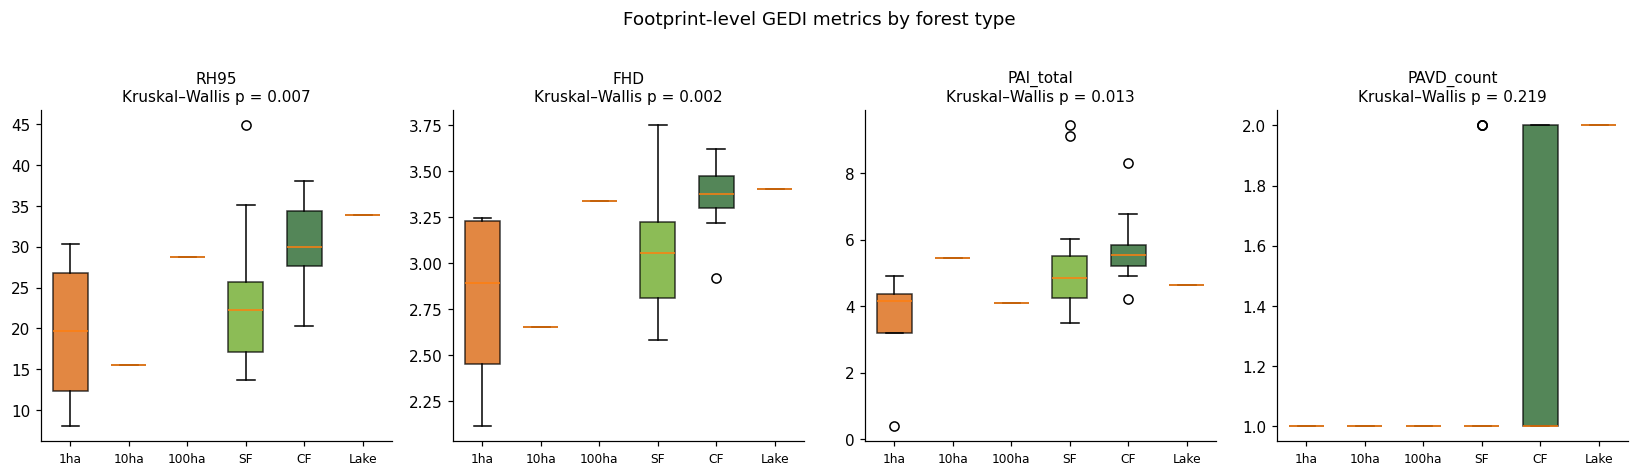

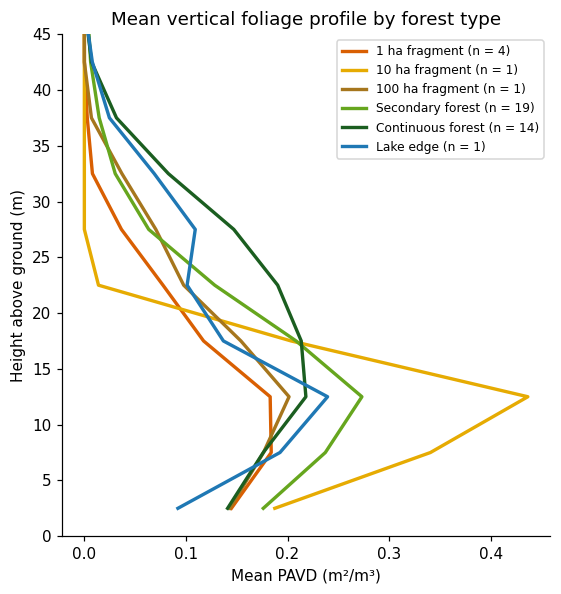

In [ ]:
show = ["RH95", "FHD", "PAI_total", "PAVD_count"]
fig, axes = plt.subplots(1, len(show), figsize=(15, 4.2))
for ax, m in zip(axes, show):
    data = [in_units.loc[in_units["habitat"] == h, m].dropna() for h in order]
    bp = ax.boxplot(data, tick_labels=order, patch_artist=True, widths=0.6)
    for patch, h in zip(bp["boxes"], order):
        patch.set_facecolor(HABITAT_COLORS[h])
        patch.set_alpha(0.75)
    groups = [d for d in data if len(d) > 1]
    p = kruskal(*groups).pvalue if len(groups) > 1 else np.nan
    ax.set_title(f"{m}\nKruskal–Wallis p = {p:.3f}", fontsize=10)
    ax.tick_params(axis="x", labelsize=8)
plt.suptitle("Footprint-level GEDI metrics by forest type", y=1.02)
plt.tight_layout()
plt.show()

# Mean vertical profile by habitat type
fig, ax = plt.subplots(figsize=(5.2, 5.5))
for h in order:
    prof = np.vstack(in_units.loc[in_units["habitat"] == h, "pavd_z"].values)
    ax.plot(np.nanmean(prof, axis=0), heights, color=HABITAT_COLORS[h], lw=2.2,
            label=f"{HABITAT_LABELS[h]} (n = {len(prof)})")
ax.set_ylim(0, 45)
ax.set_xlabel("Mean PAVD (m²/m³)")
ax.set_ylabel("Height above ground (m)")
ax.set_title("Mean vertical foliage profile by forest type")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Sanity check against the published values
Luther et al. (2026) report these habitat means (± SD). Lake-edge units sit within continuous forest and have no published values.

In [ ]:
published = pd.DataFrame({
    "habitat": ["CF", "SF", "100ha", "10ha", "1ha"],
    "RH95_paper": ["26.32 ± 5.10", "21.75 ± 4.43", "19.46 ± 6.00", "18.21 ± 7.25", "18.60 ± 5.48"],
    "FHD_paper": ["3.15 ± 0.15", "2.99 ± 0.19", "2.87 ± 0.30", "2.72 ± 0.31", "2.76 ± 0.32"],
}).set_index("habitat")
ours = in_units.groupby("habitat")[["RH95", "FHD"]].agg(["mean", "std", "size"])
#fmt = lambda h, m: (f"{ours.loc[h, (m, 'mean')]:.2f} ± {ours.loc[h, (m, 'std')]:.2f}" if h in ours.index else "–")
def fmt(h, m):
    """Mean ± SD; mean only when a habitat has a single footprint (SD undefined)."""
    if h not in ours.index:
        return "–"
    mean, sd = ours.loc[h, (m, "mean")], ours.loc[h, (m, "std")]
    return f"{mean:.2f}" if pd.isna(sd) else f"{mean:.2f} ± {sd:.2f}"

published["RH95_this_notebook"] = [fmt(h, "RH95") for h in published.index]
published["FHD_this_notebook"] = [fmt(h, "FHD") for h in published.index]
published["n_footprints"] = [int(ours.loc[h, ("FHD", "size")]) if h in ours.index else 0 for h in published.index]
published

,RH95_paper,FHD_paper,RH95_this_notebook,FHD_this_notebook,n_footprints
habitat,,,,,
CF,26.32 ± 5.10,3.15 ± 0.15,30.66 ± 5.11,3.37 ± 0.18,14
SF,21.75 ± 4.43,2.99 ± 0.19,23.57 ± 8.16,3.06 ± 0.31,19
100ha,19.46 ± 6.00,2.87 ± 0.30,28.73,3.34,1
10ha,18.21 ± 7.25,2.72 ± 0.31,15.47,2.65,1
1ha,18.60 ± 5.48,2.76 ± 0.32,19.44 ± 10.33,2.79 ± 0.55,4


## 9. Export the site-level table for Demo 3

Demo 3 links these structure metrics to bird and mammal occupancy. We save one row per sampling unit with GEDI coverage, giving the mean of each GEDI metric (the 12 candidate predictors used by Luther et al., 2026, plus RH98 and the number of canopy layers).

In [ ]:
SITE_METRICS = ["FHD", "RH95", "AGBD", "PAVD_total", "PAI_total", "Cover_total", "PAVD_15m", "PAVD_25m",
                "Cover_ratio", "PAVD_5m", "PAVD_ratio", "PAI_ratio", "RH98", "PAVD_count"]
cols = [m for m in SITE_METRICS if m in in_units]
site = (in_units.groupby(["unit_id", "reserve_name", "habitat"])[cols].mean().reset_index()
        .merge(coverage[["n_footprints", "n_orbits"]], left_on="unit_id", right_index=True))
site["habitat"] = pd.Categorical(site["habitat"], HABITAT_ORDER, ordered=True)
site = site.sort_values(["habitat", "unit_id"]).reset_index(drop=True)
out_csv = os.path.join(OUT_DIR, "site_gedi_metrics.csv")
site.to_csv(out_csv, index=False)
print(f"Saved {len(site)} sampling units to {out_csv}")
print(f"Also saved: {os.path.join(OUT_DIR, 'devices.csv')} (device locations for Demo 3)")
if "AGBD" not in cols:
    print("Note: AGBD not included – set INCLUDE_L4A = True to add GEDI L4A biomass.")
display(site.round(2))

Saved 13 sampling units to /content/drive/MyDrive/ARSET_GEDI_Biodiversity/site_gedi_metrics.csv
Also saved: /content/drive/MyDrive/ARSET_GEDI_Biodiversity/devices.csv (device locations for Demo 3)
Note: AGBD not included – set INCLUDE_L4A = True to add GEDI L4A biomass.


,unit_id,reserve_name,habitat,FHD,RH95,PAVD_total,PAI_total,Cover_total,PAVD_15m,PAVD_25m,Cover_ratio,PAVD_5m,PAVD_ratio,PAI_ratio,RH98,PAVD_count,n_footprints,n_orbits
0,CO-1,Colosso,1ha,2.68,19.200001,2.83,2.65,0.54,0.13,0.03,4.80,0.10,2.43,3.69,21.200001,1.00,2,2
1,D-1A,Dimona,1ha,2.57,13.800000,4.84,4.14,0.87,0.07,0.00,5.80,0.34,2.20,1.95,14.660000,1.00,1,1
2,D-1B,Dimona,1ha,3.22,25.580000,4.58,4.19,0.88,0.14,0.08,1.29,0.20,0.61,0.48,27.010000,1.00,1,1
3,PA-10,Porto Alegre,10ha,2.65,15.470000,5.91,5.44,0.93,0.20,0.00,2.17,0.34,1.21,0.60,16.780001,1.00,1,1
4,D-100A,Dimona,100ha,3.34,28.730000,4.44,4.08,0.87,0.15,0.07,1.29,0.18,0.69,0.49,30.450001,1.00,1,1
5,D-SF2,Dimona,SF,2.74,16.100000,4.13,3.78,0.85,0.16,0.00,3.93,0.21,1.84,1.53,17.040001,1.00,4,1
6,FL-SF1,Florestal,SF,3.03,22.129999,5.18,4.76,0.91,0.19,0.05,2.66,0.24,1.17,0.77,23.500000,1.17,6,1
7,FL-SF2,Florestal,SF,2.96,20.280001,5.66,5.24,0.92,0.27,0.02,5.25,0.24,1.78,1.28,21.420000,1.00,4,1
8,PA-SF,Porto Alegre,SF,3.43,33.919998,7.64,7.08,0.96,0.22,0.16,3.65,0.26,0.85,0.71,35.480000,1.40,5,1
9,CF-CFB,Cabo Frio,CF,3.40,31.620001,6.15,5.78,0.94,0.21,0.15,4.01,0.18,1.24,0.95,32.810001,1.45,11,2


In [ ]:
# Export the footprint table as CSV: one row per GEDI footprint, all quality flags, plus a passes_qc column
# (the Section 5 filter). 5 m profiles are spread into columns, e.g. pavd_z_10_15m = PAVD at 10–15 m.
PROFILES = ["pavd_z", "pai_z", "cover_z"]
csv_df = shots.drop(columns=PROFILES).assign(passes_qc=qc.values)
for var in PROFILES:
    arr = np.vstack(shots[var].values)
    cols = [f"{var}_{i * 5}_{i * 5 + 5}m" for i in range(arr.shape[1])]
    csv_df = pd.concat([csv_df, pd.DataFrame(arr, columns=cols, index=shots.index)], axis=1)

# Fixed decimals where precision matters; all other values are written with 6 significant digits
csv_df["lat"] = csv_df["lat"].map("{:.6f}".format)            # ~0.1 m
csv_df["lon"] = csv_df["lon"].map("{:.6f}".format)
csv_df["delta_time"] = csv_df["delta_time"].map("{:.3f}".format)  # seconds since 2018-01-01

csv_path = CACHE_FILE.replace(".parquet", ".csv")
csv_df.to_csv(csv_path, index=False, float_format="%.6g")
print(f"Saved {len(csv_df):,} footprints × {csv_df.shape[1]} columns to {csv_path} "
      f"({os.path.getsize(csv_path) / 1e6:.0f} MB; {int(csv_df['passes_qc'].sum()):,} pass the quality filter)")

Saved 187,088 footprints × 112 columns to /content/drive/MyDrive/ARSET_GEDI_Biodiversity/bdffp_gedi_footprints_v003.csv (113 MB; 21,839 pass the quality filter)


NOTE: our table has far fewer footprints per habitat than Luther et al. We have 39 inside the sampling units after filtering, with only 1 each in the 100 ha and 10 ha fragments. The paper had 117, about 8 per unit. That’s probably because your settings are stricter than theirs on both counts:
Version 3 quality flag: stricter than the Version 2 flag the paper used.
0.98 sensitivity threshold: the paper doesn’t state one.
To see how much each matters, temporarily set MIN_SENSITIVITY = 0.95, or filter on quality_flag_rel2 (the V2-era flag the notebook already keeps), and rerun from Section 5

## Key takeaways
- GEDI L2A/L2B provide footprint-level canopy height, PAI, FHD and full vertical foliage profiles across the BDFFP landscape.
- **FHD** summarizes vertical heterogeneity in one number; recomputing it from the PAVD profile shows exactly what it measures.
- **Height diversity** (variation in canopy height among footprints) adds a horizontal dimension of structural complexity.
- Mature continuous forest is expected to be taller with higher FHD than secondary forest and small fragments, matching Luther et al. (2026).
- GEDI samples the landscape with discrete footprints, so maps show sampled cells rather than wall-to-wall coverage.

**Next (Demo 3):** use these site-level metrics to model bird and mammal occupancy.